# 🏀 NBA Player Finder — saison par saison (2012–2022)

**Objectif :** trouver, dans chaque équipe NBA, le joueur au **style statistique** le plus proche d’un joueur de référence ; afficher séparément sa **performance** et ses **12 archétypes**.

**Méthode :** recherche par similarité de profils (pas besoin d’entraîner un réseau de neurones). Les scores sont des **indices relatifs à la saison, expérimentaux**, et non des probabilités ni des notes NBA officielles. Les informations avancées (défense réelle, localisation des tirs, tirs après dribble) ne figurent pas dans les données.

**Mode d’emploi :** mettre ce notebook à côté de `nba_moyennes_2012_2022.csv` (ou `.xlsx`), puis exécuter les cellules de haut en bas. La saison 2022–23 peut être partielle dans ce fichier. Pour une démo fiable, commencer par **2021-22**.

## 1. Bibliothèques et chargement
Si besoin : `pip install pandas numpy scikit-learn matplotlib openpyxl`

In [1]:
import sys
print(sys.executable)
print(sys.version)

/opt/miniconda3/envs/tensorflow39/bin/python
3.9.25 (main, Nov  3 2025, 22:29:32) 
[Clang 20.1.8 ]


In [5]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("TensorFlow :", tf.__version__)

Pandas : 2.3.3
NumPy : 2.0.2
Scikit-learn : 1.6.1
TensorFlow : 2.20.0


In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import RobustScaler

CSV = Path('nba_moyennes_2012_2022.csv')
XLSX = Path('nba_moyennes_2012_2022.xlsx')
if CSV.exists():
    data = pd.read_csv(CSV)
elif XLSX.exists():
    data = pd.read_excel(XLSX)
else:
    raise FileNotFoundError('Place nba_moyennes_2012_2022.csv ou .xlsx dans le dossier du notebook.')

print(f'{len(data):,} lignes, {len(data.columns)} colonnes')
print('Saisons :', ', '.join(sorted(data.SAISON.astype(str).unique())))
display(data.head(3))

6,367 lignes, 28 colonnes
Saisons : 2012-13, 2013-14, 2014-15, 2015-16, 2016-17, 2017-18, 2018-19, 2019-20, 2020-21, 2021-22, 2022-23


,SAISON,PLAYER_ID,JOUEUR,EQUIPE,MJ,TITULARISATIONS,%_TITULARISATION,MIN_MOY,PTS_MOY,REB_MOY,...,FGA_MOY,FG%,3PM_MOY,3PA_MOY,3P%,FTM_MOY,FTA_MOY,FT%,PLUS_MINUS_MOY,PTS_36MIN
0,2012-13,101106,Andrew Bogut,GSW,32,32,100.00,24.55,5.812,7.656,...,5.750,45.11,0.031,0.031,100.00,0.594,1.188,50.00,1.156,8.52
1,2012-13,101107,Marvin Williams,UTA,73,51,69.86,23.66,7.247,3.603,...,6.438,42.34,0.740,2.274,32.53,1.055,1.356,77.78,-1.315,11.03
2,2012-13,101108,Chris Paul,LAC,70,70,100.00,33.36,16.943,3.743,...,12.229,48.13,1.086,3.314,32.76,4.086,4.614,88.54,6.171,18.29


## 2. Vérification des données et sélection d’une saison
Une ligne correspond au couple **joueur–équipe–saison**. Un joueur transféré peut apparaître plusieurs fois.

In [8]:
colonnes = ['SAISON','PLAYER_ID','JOUEUR','EQUIPE','MJ','TITULARISATIONS','%_TITULARISATION',
    'MIN_MOY','PTS_MOY','REB_MOY','AST_MOY','STL_MOY','BLK_MOY','TO_MOY',
    'OREB_MOY','DREB_MOY','FGA_MOY','FGM_MOY','FG%','3PM_MOY','3PA_MOY','3P%',
    'FTM_MOY','FTA_MOY','FT%']
manquantes = sorted(set(colonnes) - set(data.columns))
if manquantes:
    raise ValueError('Colonnes absentes : ' + ', '.join(manquantes))
num = [x for x in colonnes if x not in ('SAISON','PLAYER_ID','JOUEUR','EQUIPE')]
for column in num:
    data[column] = pd.to_numeric(data[column], errors='coerce')
print('Valeurs manquantes par colonne (non nulles) :')
print(data.isna().sum().loc[lambda s: s > 0].to_string() or 'Aucune')
print('\nNombre de lignes par saison :')
display(data.groupby('SAISON').agg(lignes=('JOUEUR','size'), equipes=('EQUIPE','nunique')))

SAISON = '2021-22'
JOUEUR = 'Klay Thompson'
MIN_MATCHS = 10   # seuil de fiabilité des profils candidats ; modifiable
MIN_MINUTES = 10  # minutes moyennes par match ; modifiable
assert SAISON in set(data.SAISON), 'Saison indisponible'
base = data.loc[data.SAISON.eq(SAISON)].copy().reset_index(drop=True)
print(f'Saison {SAISON} : {len(base)} lignes, {base.EQUIPE.nunique()} équipes')

Valeurs manquantes par colonne (non nulles) :
FG%     52
3P%    615
FT%    410

Nombre de lignes par saison :


,lignes,equipes
SAISON,,
2012-13,523,30
2013-14,548,30
2014-15,575,30
2015-16,528,30
2016-17,542,30
2017-18,605,30
2018-19,622,30
2019-20,592,30
2020-21,626,30


Saison 2021-22 : 717 lignes, 30 équipes


## 3. Construire les variables de style
Les statistiques par 36 minutes rendent comparables les rythmes de jeu individuels ; les parts de tirs mesurent les préférences (3 points, lancers). Un taux à 3 points basé sur très peu de tentatives est **lissé** vers la moyenne de saison. Le style doit être distingué du niveau.

In [9]:
def div(a, b):
    return np.divide(a, b, out=np.zeros_like(np.asarray(a, dtype=float)), where=np.asarray(b, dtype=float) > 0)

def construire_variables(df):
    d = df.copy()
    minutes = d['MIN_MOY'].clip(lower=1)
    for stat in ['PTS','AST','REB','STL','BLK','TO','OREB','DREB','FGA','3PA','3PM','FTA']:
        d[f'{stat}_36'] = d[f'{stat}_MOY'] * 36 / minutes
    d['PART_3PTS'] = div(d['3PA_MOY'].to_numpy(), d['FGA_MOY'].to_numpy())
    d['PART_LF'] = div(d['FTA_MOY'].to_numpy(), d['FGA_MOY'].to_numpy())
    d['RATIO_AST_TO'] = div(d['AST_MOY'].to_numpy(), (d['AST_MOY'] + d['TO_MOY'] + .5).to_numpy())
    # TS% = PTS/[2*(FGA+0,44*FTA)], estimation standard
    d['TS'] = div(d['PTS_MOY'].to_numpy(), (2*(d['FGA_MOY'] + .44*d['FTA_MOY'])).to_numpy())
    # Pourcentages lissés : prior équivalent à 4 tentatives à 3 pts par match
    p3_global = div(np.array([d['3PM_MOY'].sum()]), np.array([d['3PA_MOY'].sum()]))[0]
    d['ADRESSE_3PTS_LISSEE'] = div((d['3PM_MOY'] + 4*p3_global).to_numpy(), (d['3PA_MOY'] + 4).to_numpy())
    return d.replace([np.inf,-np.inf],np.nan)

base = construire_variables(base)
STYLE = {
    'PTS_36': 1.2, 'AST_36': 1.2, 'REB_36': .8, 'STL_36': .65, 'BLK_36': .65,
    'OREB_36': .7, 'FGA_36': .9, '3PA_36': 1.1, 'PART_3PTS': 1.5,
    'PART_LF': .6, 'RATIO_AST_TO': .7, 'ADRESSE_3PTS_LISSEE': .6
}
print('Variables de similarité :', list(STYLE))

Variables de similarité : ['PTS_36', 'AST_36', 'REB_36', 'STL_36', 'BLK_36', 'OREB_36', 'FGA_36', '3PA_36', 'PART_3PTS', 'PART_LF', 'RATIO_AST_TO', 'ADRESSE_3PTS_LISSEE']


## 4. Deux scores indépendants
**Similarité :** distance pondérée entre variables de style standardisées. La conversion en note de 0 à 100 est une échelle pratique, sans interprétation probabiliste.

**Performance :** agrégation de rangs percentiles (production, efficacité, passes, rebonds, interceptions et contres) corrigée par le temps de jeu. Cela mesure une performance *statistique* et non la qualité défensive ou l’impact réel. Le `+/-` brut est écarté car très influencé par les coéquipiers.

In [10]:
def _percentile(s):
    return s.rank(pct=True).fillna(.5)

def score_performance(df):
    # Poids explicites, modifiables. Un joueur de peu de minutes est légèrement pénalisé.
    poids = {'PTS_36': .25, 'TS': .20, 'AST_36': .15, 'REB_36': .12,
             'STL_36': .10, 'BLK_36': .10, 'RATIO_AST_TO': .08}
    total = sum(_percentile(df[k]) * w for k, w in poids.items())
    fiabilite = (.75 + .25 * (df['MIN_MOY'].clip(0,30)/30))
    return (100 * total * fiabilite).clip(0,100).round(1)

base['PERFORMANCE'] = score_performance(base)

def trouver_joueur(df, nom, equipe=None):
    resultats = df[df['JOUEUR'].str.casefold().eq(nom.casefold())]
    if equipe:
        resultats = resultats[resultats.EQUIPE.eq(equipe)]
    if resultats.empty:
        suggestions = df[df.JOUEUR.str.contains(nom,case=False,na=False,regex=False)]['JOUEUR'].unique()[:12]
        raise ValueError(f'Joueur absent : {nom}. Suggestions : {list(suggestions)}')
    # En cas de transfert, utiliser la ligne avec le plus de matchs comme référence
    return resultats.sort_values('MJ',ascending=False).iloc[0]

def rechercher_similaires(df, joueur, mode='similarite', minimum_similarite=70,
                           min_matchs=MIN_MATCHS, min_minutes=MIN_MINUTES):
    reference = trouver_joueur(df,joueur)
    admissibles = df[(df.MJ >= min_matchs) & (df.MIN_MOY >= min_minutes)].copy()
    if admissibles.empty:
        raise ValueError('Aucun candidat : diminuer les seuils de matchs ou de minutes.')
    # Ajuster les échelles sur les candidats de la saison ; robustes aux valeurs extrêmes
    matrice = pd.concat([admissibles,reference.to_frame().T],ignore_index=True)
    X = matrice[list(STYLE)].apply(pd.to_numeric,errors='coerce')
    X = X.fillna(X.median()).fillna(0)
    scaler = RobustScaler()
    z = np.clip(scaler.fit_transform(X),-5,5)
    poids = np.array(list(STYLE.values()))
    distance = np.sqrt(np.average((z[:-1] - z[-1])**2,axis=1,weights=poids))
    # échelle descriptive commune, pas un pourcentage de chance
    admissibles['SIMILARITE'] = np.round(100*np.exp(-distance/1.5),1)
    # On exclut le même joueur, identifié par PLAYER_ID sur toutes ses équipes
    admissibles = admissibles[admissibles.PLAYER_ID != reference.PLAYER_ID]
    if mode == 'performance':
        admissibles = admissibles[admissibles.SIMILARITE >= minimum_similarite]
        if admissibles.empty:
            return admissibles
        ordre = ['PERFORMANCE','SIMILARITE']
    elif mode == 'similarite':
        ordre = ['SIMILARITE','PERFORMANCE']
    else:
        raise ValueError("mode doit être 'similarite' ou 'performance'")
    return (admissibles.sort_values(ordre,ascending=False)
            .drop_duplicates('EQUIPE')
            [['EQUIPE','JOUEUR','MJ','MIN_MOY','SIMILARITE','PERFORMANCE','PTS_MOY','3PA_MOY','AST_MOY']]
            .sort_values(ordre,ascending=False).reset_index(drop=True))

print('Référence :')
display(base.loc[base.JOUEUR.eq(JOUEUR),['JOUEUR','EQUIPE','MJ','PTS_MOY','3PA_MOY','3P%','PERFORMANCE']])
print('Meilleur profil similaire par équipe :')
resultats = rechercher_similaires(base, JOUEUR)
display(resultats)

Référence :


,JOUEUR,EQUIPE,MJ,PTS_MOY,3PA_MOY,3P%,PERFORMANCE
597,Klay Thompson,GSW,32,20.375,9.25,38.51,61.4


Meilleur profil similaire par équipe :


,EQUIPE,JOUEUR,MJ,MIN_MOY,SIMILARITE,PERFORMANCE,PTS_MOY,3PA_MOY,AST_MOY
0,CHA,Isaiah Thomas,16,13.35,77.3,55.2,8.625,3.500,1.500
1,POR,CJ McCollum,36,35.19,71.8,63.1,20.528,8.028,4.528
2,MIA,Tyler Herro,66,32.59,68.9,61.7,20.712,6.652,3.985
3,GSW,Jordan Poole,76,30.04,68.4,66.8,18.487,7.632,4.000
4,BOS,Jayson Tatum,76,35.93,67.7,73.4,26.921,8.566,4.395
5,UTA,Jordan Clarkson,79,27.10,67.2,56.5,16.025,7.557,2.456
6,CHI,Zach LaVine,66,34.82,66.8,67.5,24.424,7.136,4.485
7,MIN,Anthony Edwards,72,34.25,66.1,69.2,21.292,8.361,3.819
8,BKN,Kyrie Irving,29,37.64,65.7,74.1,27.448,8.241,5.759
9,PHX,Devin Booker,68,34.48,65.3,71.8,26.794,7.029,4.838


## 5. Classement alternatif : meilleurs joueurs ayant un style proche
Le seuil sert à **ne pas présenter un joueur très performant mais sans vraie ressemblance**. Il peut arriver qu’une équipe n’ait aucun candidat ; c’est normal.

In [11]:
SEUIL_SIMILARITE = 65  # ajustable après inspection de la distribution
meilleurs = rechercher_similaires(base, JOUEUR, mode='performance', minimum_similarite=SEUIL_SIMILARITE)
print(f'Équipes avec au moins un joueur similaire à {SEUIL_SIMILARITE}/100 : {len(meilleurs)}')
display(meilleurs)

Équipes avec au moins un joueur similaire à 65/100 : 11


,EQUIPE,JOUEUR,MJ,MIN_MOY,SIMILARITE,PERFORMANCE,PTS_MOY,3PA_MOY,AST_MOY
0,GSW,Stephen Curry,64,34.55,66.2,77.1,25.469,11.719,6.312
1,BKN,Kyrie Irving,29,37.64,65.7,74.1,27.448,8.241,5.759
2,BOS,Jayson Tatum,76,35.93,67.7,73.4,26.921,8.566,4.395
3,PHX,Devin Booker,68,34.48,65.3,71.8,26.794,7.029,4.838
4,MEM,Desmond Bane,76,29.82,65.3,70.8,18.211,6.882,2.737
5,UTA,Donovan Mitchell,67,33.82,65.4,69.8,25.866,9.761,5.343
6,MIN,Anthony Edwards,72,34.25,66.1,69.2,21.292,8.361,3.819
7,CHA,Terry Rozier,72,33.72,65.5,68.7,19.347,8.153,4.417
8,CHI,Zach LaVine,66,34.82,66.8,67.5,24.424,7.136,4.485
9,POR,CJ McCollum,36,35.19,71.8,63.1,20.528,8.028,4.528


## 6. Les 12 archétypes (approximations statistiques)
Ces notes sont calculées **par saison**, relativement aux autres joueurs. Plusieurs archétypes peuvent s’appliquer au même joueur.

⚠️ **Limites :** `3&D` et `Two-Way` utilisent interceptions/contres comme *indices imparfaits* de défense. `Point Forward` suppose un poste d’ailier, mais le fichier ne comporte pas de poste : on repère seulement un **profil de grand créateur**, sans certifier le poste. `Stretch Big` suppose un intérieur, mais sans taille ou poste on utilise les rebonds comme substitut. `Sixth Man` est un **rôle** (sortie de banc), pas un style ; il est approché à partir des titularisations et des minutes.

Archétypes principaux : {'Sharpshooter': 91.3, 'Microwave Scorer': 88.4, 'Scorer': 86.8, 'Stretch Big': 74.2, 'Playmaker': 68.0}


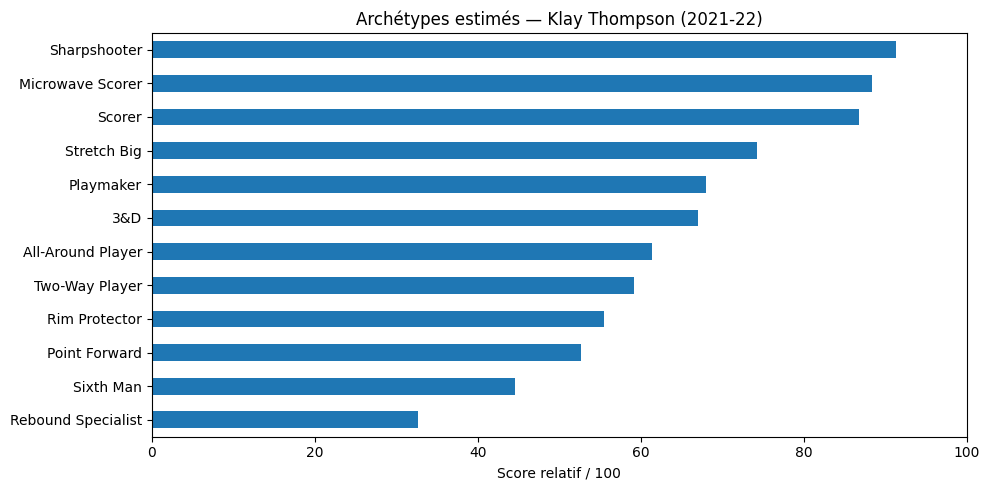

In [12]:
ARCHETYPES = [
 '3&D','Sharpshooter','Playmaker','Scorer','Rim Protector','Rebound Specialist',
 'Two-Way Player','All-Around Player','Stretch Big','Point Forward','Microwave Scorer','Sixth Man'
]

def calculer_archetypes(df):
    d = df.copy()
    p = lambda col: 100*_percentile(d[col])
    notes = pd.DataFrame(index=d.index)
    notes['3&D'] = .30*p('3PA_36')+.25*p('ADRESSE_3PTS_LISSEE')+.30*p('STL_36')+.15*p('BLK_36')
    notes['Sharpshooter'] = .50*p('3PA_36')+.35*p('ADRESSE_3PTS_LISSEE')+.15*p('PART_3PTS')
    notes['Playmaker'] = .65*p('AST_36')+.35*p('RATIO_AST_TO')
    notes['Scorer'] = .65*p('PTS_36')+.20*p('TS')+.15*p('FGA_36')
    notes['Rim Protector'] = .75*p('BLK_36')+.25*p('DREB_36')
    notes['Rebound Specialist'] = .75*p('REB_36')+.25*p('OREB_36')
    notes['Two-Way Player'] = .50*(.65*p('PTS_36')+.35*p('AST_36')) + .50*(.65*p('STL_36')+.35*p('BLK_36'))
    notes['All-Around Player'] = .30*p('PTS_36')+.25*p('AST_36')+.25*p('REB_36')+.10*p('STL_36')+.10*p('BLK_36')
    notes['Stretch Big'] = .35*p('REB_36')+.40*p('3PA_36')+.25*p('ADRESSE_3PTS_LISSEE')
    notes['Point Forward'] = .40*p('REB_36')+.60*p('AST_36')
    notes['Microwave Scorer'] = .65*p('PTS_36')+.25*p('FGA_36')+.10*(100-p('MIN_MOY'))
    banc = (100 - d['%_TITULARISATION'].clip(0,100)).fillna(0)
    notes['Sixth Man'] = .50*banc+.25*p('MIN_MOY')+.25*p('PTS_36')
    # Les manquants de statut titulaire ne sont pas interprétés comme des remplaçants.
    notes.loc[d['%_TITULARISATION'].isna(),'Sixth Man'] = np.nan
    return notes.clip(0,100).round(1)

scores_arch = calculer_archetypes(base)
base = pd.concat([base,scores_arch],axis=1)
profil = trouver_joueur(base, JOUEUR)
print('Archétypes principaux :',profil[ARCHETYPES].sort_values(ascending=False).head(5).to_dict())

fig, ax = plt.subplots(figsize=(10,5))
profil[ARCHETYPES].sort_values().plot.barh(ax=ax)
ax.set(xlabel='Score relatif / 100',title=f'Archétypes estimés — {JOUEUR} ({SAISON})',xlim=(0,100))
plt.tight_layout()
plt.show()

## 7. Comparer visuellement deux joueurs
Choisis un joueur renvoyé par la recherche précédente, ou laisse le notebook en sélectionner un automatiquement.

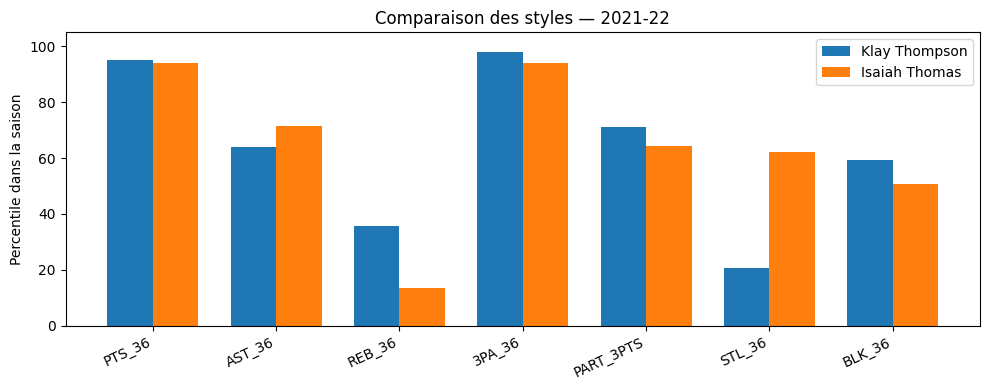

In [13]:
comparaison = resultats.iloc[0]['JOUEUR'] if len(resultats) else JOUEUR
p1 = trouver_joueur(base,JOUEUR)
p2 = trouver_joueur(base,comparaison)
vars_plot = ['PTS_36','AST_36','REB_36','3PA_36','PART_3PTS','STL_36','BLK_36']
# Percentiles communs à la saison pour comparer des échelles très différentes
rangs = pd.DataFrame({k:100*_percentile(base[k]) for k in vars_plot})
fig, ax = plt.subplots(figsize=(10,4))
x = np.arange(len(vars_plot)); w=.37
ax.bar(x-w/2,rangs.loc[p1.name,vars_plot],width=w,label=JOUEUR)
ax.bar(x+w/2,rangs.loc[p2.name,vars_plot],width=w,label=comparaison)
ax.set_xticks(x,vars_plot,rotation=25,ha='right'); ax.set_ylabel('Percentile dans la saison')
ax.set_ylim(0,105);ax.legend();ax.set_title(f'Comparaison des styles — {SAISON}')
plt.tight_layout();plt.show()

## 8. Recherche libre et exportation
Modifie les paramètres, réexécute la cellule. `similaires` sélectionne le plus proche dans chaque équipe ; `meilleurs` sélectionne le plus performant parmi ceux dépassant le seuil.

In [14]:
joueur_recherche = 'Stephen Curry'
saison_recherche = '2021-22'
mode_recherche = 'similarite'  # ou 'performance'
seuil = 65

saison_df = construire_variables(data[data.SAISON.eq(saison_recherche)].copy().reset_index(drop=True))
saison_df['PERFORMANCE'] = score_performance(saison_df)
saison_df = pd.concat([saison_df, calculer_archetypes(saison_df)],axis=1)
resultat_final = rechercher_similaires(saison_df, joueur_recherche,
                                      mode=mode_recherche, minimum_similarite=seuil)
display(resultat_final)
resultat_final.to_csv('resultats_nba.csv',index=False,encoding='utf-8-sig')
print('Export effectué : resultats_nba.csv')

,EQUIPE,JOUEUR,MJ,MIN_MOY,SIMILARITE,PERFORMANCE,PTS_MOY,3PA_MOY,AST_MOY
0,UTA,Donovan Mitchell,67,33.82,77.5,69.8,25.866,9.761,5.343
1,CHA,Isaiah Thomas,16,13.35,69.9,55.2,8.625,3.500,1.500
2,GSW,Jordan Poole,76,30.04,69.4,66.8,18.487,7.632,4.000
3,TOR,Fred VanVleet,64,37.85,69.0,68.9,20.469,9.953,6.656
4,BKN,Kyrie Irving,29,37.64,68.1,74.1,27.448,8.241,5.759
5,MIN,Anthony Edwards,72,34.25,67.4,69.2,21.292,8.361,3.819
6,DEN,Bones Hyland,69,18.98,67.3,60.7,10.116,5.188,2.768
7,NOP,CJ McCollum,26,33.78,66.9,72.1,24.269,6.923,5.846
8,BOS,Jayson Tatum,76,35.93,66.0,73.4,26.921,8.566,4.395
9,POR,Damian Lillard,29,36.42,65.7,63.6,23.966,9.793,7.310


Export effectué : resultats_nba.csv


## 9. Pistes d'amélioration

1. **Valider les archétypes** en examinant les meilleurs joueurs de chaque catégorie : les notes sont pour l’instant des heuristiques, **pas une classification entraînée ni validée**.
2. **Tester les pondérations et le seuil** à partir de paires de joueurs jugés proches par des connaisseurs ; mesurer la stabilité des résultats.
3. **Ajouter poste, taille et statistiques avancées** (tirs au cercle / mi-distance, possessions, statistiques défensives, % des tirs assistés) pour fiabiliser `Stretch Big`, `Point Forward`, `3&D` et la création de tirs.
4. **Mesurer l’incertitude** sur les joueurs ayant peu de matchs (filtre configurable) ; comparer éventuellement plusieurs saisons, mais **pas mélanger les saisons** dans une même recherche.
5. **Créer une interface Streamlit** lorsque le notebook fonctionne comme prévu.

**Précautions :** le score de similarité **n'exprime pas une probabilité**, le score de performance n'est **pas un classement objectif de talent**, et les moyennes d'un joueur transféré sont calculées séparément pour chaque équipe.